<a href="https://colab.research.google.com/github/MhiyaJ/My-GIS-Stuff/blob/main/After%20School%20Programs%20PS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **IMPORT LIBRARY, SET-UP DATA FRAME**

In [94]:
%%capture
#!pip install geopandas #==1.0.1
#!pip install mapclassify #sometimes have to install library which you get from https://pypi.org/

In [95]:
import os, zipfile #basics
import pandas as pd #data management
import matplotlib.pyplot as plt #vis

import geopandas as gpd #gis/maps: a sister of pandas; does the job;
#tho not as fancy-interactive as folium or leafmap https://geopandas.org/

import mapclassify #need for thematic map classification

import seaborn as sns

#will display all output not just last command
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files #to download from colab onto hd

#from google.colab import data_table
#data_table.enable_dataframe_formatter() #this enables spreadsheet view upon calling dataframe (without() )
from google.colab.data_table import DataTable
DataTable.max_columns = 250

In [96]:
#!python --version
gpd.__version__

'1.2.0'

### **HYPOTHESIS**

Students living in urban areas with limited access to affordable after-school programs are more likely to experience social disengagement and engage in delinquent behavior than students with greater access to these programs.

### **PROJECT DESCRIPTION:**

Identifying the availability and accessibility of after school programs in low income areas and examining their relationship to youth social disengagement and delinquent behaviors.

Variables: After school programs, economically disadvantaged youth population, delinquent/disengaged behavior, household income

### **NEW JERSEY MUNICIPALITY SHAPEFILE**

Listed as school districts for most files, merged into municipalities by using first word from each renamed Muni column

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

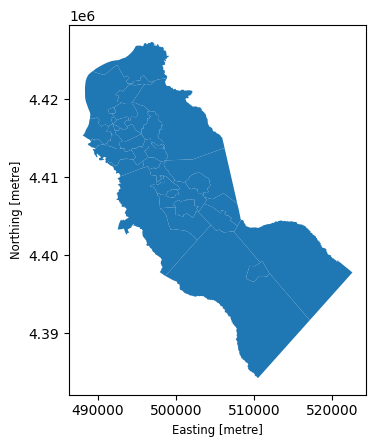

In [97]:
#Camden County Open Data Portal
#https://camdencountynj-ccdpw.opendata.arcgis.com/datasets/CCDPW::municipalities/about
#code used from class
! wget -q -O Municipalities.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Municipalities.zip

zip_ref = zipfile.ZipFile('Municipalities.zip', 'r'); zip_ref.extractall(); zip_ref.close()

njMun=gpd.read_file('Municipalities.shp') #labeled shapefile njMun
#Camden County Municipal shapefile better use than NJ school district shapefile
njMun.plot()

In [98]:
#identify headings of shapefile
njMun.head(2)

,FID,COUSUBNS,GEOID,NAMELSAD,CLASSFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,GEOCODE,GlobalID,Shape__Are,Shape__Len,geometry
0,1,00885144,3400702200,Audubon borough,C5,F,3838781,35535,+39.8901277,-75.0723825,9407.757950,3400702200,81d661c6-35a7-42ed-8afd-5f35d0b0e807,3.871214e+06,9407.757866,"POLYGON ((495599.23 4415536.249, 495508.749 44..."
1,2,00885145,3400702230,Audubon Park borough,C5,F,389606,46935,+39.8968373,-75.0888190,2734.677596,3400702230,f8ccbea8-76dd-44e7-992b-e367d22e31a1,4.361934e+05,2734.677499,"POLYGON ((492866.221 4416337.872, 492855.687 4..."


In [99]:
#Rename field, make renamed column upper case and select only items w/ GEO data and strip white space, split Muni into first word only
njMun.rename(columns={'NAMELSAD' : 'Muni'}, inplace=True)
njMun['Muni'] = njMun['Muni'].str.upper()
njMun.loc[njMun['Muni'] == 'GLOUCESTER CITY CITY','Muni'] = 'GLOUCESTER CITY'
njMun1 = njMun[['Muni','GEOID', 'geometry']]
njMun1['Muni']=njMun1.Muni.str.strip()
njMun1['first_word_Muni'] = njMun1['Muni'].str.split().str[0]
njMun1

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,Muni,GEOID,geometry,first_word_Muni
0,AUDUBON BOROUGH,3400702200,"POLYGON ((495599.23 4415536.249, 495508.749 44...",AUDUBON
1,AUDUBON PARK BOROUGH,3400702230,"POLYGON ((492866.221 4416337.872, 492855.687 4...",AUDUBON
2,BARRINGTON BOROUGH,3400703250,"POLYGON ((496819.374 4414558.505, 496827.878 4...",BARRINGTON
3,BELLMAWR BOROUGH,3400704750,"POLYGON ((492951.896 4413667.751, 492968.147 4...",BELLMAWR
4,BERLIN BOROUGH,3400705440,"POLYGON ((507881.319 4403761.193, 507873.371 4...",BERLIN
5,BERLIN TOWNSHIP,3400705470,"POLYGON ((507848.567 4406644.366, 507978.687 4...",BERLIN
6,BROOKLAWN BOROUGH,3400708170,"POLYGON ((490740.818 4414218.502, 490736.285 4...",BROOKLAWN
7,CAMDEN CITY,3400710000,"POLYGON ((493032.266 4419551.728, 492897.768 4...",CAMDEN
8,CHERRY HILL TOWNSHIP,3400712280,"POLYGON ((506224.674 4413748.279, 506174.32 44...",CHERRY
9,CHESILHURST BOROUGH,3400712550,"POLYGON ((512006.451 4397643.342, 512016.246 4...",CHESILHURST


### **AFTER SCHOOL PROGRAM LOCATIONS**

In [100]:
PrgXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/After%20School%20Programs.2.xlsx')

In [101]:
PrgXls.head()

,After School Programs,Address,Unnamed: 2
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health


In [102]:
#Rename columns and separated program types
PrgXls = PrgXls.rename(columns={'Unnamed: 2': 'Prog Type'})
PrgFsc = PrgXls[PrgXls['Prog Type'].str.strip() == 'Family Success Center']
PrgCom = PrgXls[PrgXls['Prog Type'].str.strip() == 'Community Center']
PrgGen = PrgXls[PrgXls['Prog Type'].str.strip() == 'General']
PrgHea = PrgXls[PrgXls['Prog Type'].str.strip() == 'Health']
PrgXls

,After School Programs,Address,Prog Type
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health
5,Collingswood Early Childhood Center,"201 Dayton Ave., Collingswood, NJ 08108",Health
6,Parkview Preschool,"700 W. Browning Rd., Collingswood, NJ 08107",Health
7,Oaklyn Public School,"136 Kendall Blvd., Oaklyn, NJ 08107",Health
8,"After-School All-Stars, Copewood Campus","1650 Copewood St., Camden, NJ 08103",General
9,"After-School All-Stars, Mt. Ephraim Campus","1575 Mt. Ephraim Ave., Camden, NJ 08104",General


In [103]:
from geopandas.tools import geocode

In [104]:
# Combine 'Address' and 'City' into a single string for better geocoding accuracy
full_addresses = PrgXls['Address'].astype(str) + ", New Jersey"

# Geocode using 'arcgis' provider to avoid Nominatim's strict 429 rate limiting
geo = geocode(full_addresses, provider='arcgis', timeout=10)
geo.head(3)

,geometry,address
0,POINT (-75.06635 39.9196),"265 Lincoln Ave, Collingswood, New Jersey, 08108"
1,POINT (-75.08938 39.91174),"400 Comly Ave, Oaklyn, New Jersey, 08107"
2,POINT (-75.07578 39.91817),"480 Haddon Ave, Collingswood, New Jersey, 08108"


### **MEDIAN HOUSEHOLD INCOME**
Analyze data for affordability to after school programs

In [105]:
#Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Inflation Adjusted Dollars), 2024. Prepared by Social Explorer. https://www.socialexplorer.com/data/ACS2024_5yr/metadata?ds=SE&table=A14006 (accessed 27 September 2026 at 10:01:00 GMT-4).
IncXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Median%20Household%20Income.xlsx', header=3, nrows=36)

In [106]:
#identify headings of Excel file
IncXls.head()

,SE:A14006:Median Household Income (In 2024 Inflation Adjusted Dollars),Unnamed: 1
0,"Audubon borough, Camden County, New Jersey",115789
1,"Audubon Park borough, Camden County, New Jersey",56619
2,"Barrington borough, Camden County, New Jersey",87290
3,"Bellmawr borough, Camden County, New Jersey",76654
4,"Berlin borough, Camden County, New Jersey",102855


In [107]:
#Rename columns, make everything upper case and clear white space.  Also remove Camden County, New Jersey with white space, #take extra city out Gloucester
#Filter for both only to show 2024-2025 SchoolYear and Camden
IncXls1=IncXls[['SE:A14006:Median Household Income (In 2024 Inflation Adjusted Dollars)','Unnamed: 1']]
IncXls1.rename(columns={'SE:A14006:Median Household Income (In 2024 Inflation Adjusted Dollars)': 'Muni'}, inplace=True)
IncXls1.rename(columns={'Unnamed: 1': 'Median Income'}, inplace=True)
IncXls1['Muni'] = IncXls1['Muni'].str.upper()
IncXls1['Muni'] = IncXls1['Muni'].str.replace(', CAMDEN COUNTY, NEW JERSEY', '', regex=False).str.strip()
IncXls1.loc[IncXls1['Muni'] == 'GLOUCESTER CITY CITY','Muni'] = 'GLOUCESTER CITY'
IncXls1

,Muni,Median Income
0,AUDUBON BOROUGH,115789
1,AUDUBON PARK BOROUGH,56619
2,BARRINGTON BOROUGH,87290
3,BELLMAWR BOROUGH,76654
4,BERLIN BOROUGH,102855
5,BERLIN TOWNSHIP,75238
6,BROOKLAWN BOROUGH,59063
7,CAMDEN CITY,40546
8,CHERRY HILL TOWNSHIP,121502
9,CHESILHURST BOROUGH,91683


In [108]:
#Regular merge on Muni, no first word separation needed
a3 = pd.merge(njMun, IncXls1, on='Muni', how='outer', indicator=True)
a3

,FID,COUSUBNS,GEOID,Muni,CLASSFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,GEOCODE,GlobalID,Shape__Are,Shape__Len,geometry,Median Income,_merge
0,1,00885144,3400702200,AUDUBON BOROUGH,C5,F,3838781,35535,+39.8901277,-75.0723825,9407.757950,3400702200,81d661c6-35a7-42ed-8afd-5f35d0b0e807,3.871214e+06,9407.757866,"POLYGON ((495599.23 4415536.249, 495508.749 44...",115789,both
1,2,00885145,3400702230,AUDUBON PARK BOROUGH,C5,F,389606,46935,+39.8968373,-75.0888190,2734.677596,3400702230,f8ccbea8-76dd-44e7-992b-e367d22e31a1,4.361934e+05,2734.677499,"POLYGON ((492866.221 4416337.872, 492855.687 4...",56619,both
2,3,00885149,3400703250,BARRINGTON BOROUGH,C5,F,4095340,0,+39.8689349,-75.0513618,11456.984021,3400703250,9e9086b1-16e4-429f-b5c4-d967de1dbd82,4.092067e+06,11456.984073,"POLYGON ((496819.374 4414558.505, 496827.878 4...",87290,both
3,4,00885154,3400704750,BELLMAWR BOROUGH,C5,F,7729295,315734,+39.8663560,-75.0946695,18085.471872,3400704750,bdd07346-3ee8-471e-befd-b8b9e16eb0a9,8.038608e+06,18085.472003,"POLYGON ((492951.896 4413667.751, 492968.147 4...",76654,both
4,5,00885158,3400705440,BERLIN BOROUGH,C5,F,9307767,35573,+39.7920594,-74.9369855,14823.777678,3400705440,032f4608-e579-4343-a5e1-7d3778ce56c5,9.335884e+06,14823.777540,"POLYGON ((507881.319 4403761.193, 507873.371 4...",102855,both
5,6,00882152,3400705470,BERLIN TOWNSHIP,T1,A,8656740,15360,+39.8071159,-74.9241780,15771.555136,3400705470,e17a4101-16d7-4093-b9da-43f1044ceef7,8.665170e+06,15771.555122,"POLYGON ((507848.567 4406644.366, 507978.687 4...",75238,both
6,7,00885172,3400708170,BROOKLAWN BOROUGH,C5,F,1265110,105763,+39.8793503,-75.1203958,5697.800517,3400708170,1e1a2ee3-3807-458d-8af0-7a2d5df7de30,1.369780e+06,5697.800436,"POLYGON ((490740.818 4414218.502, 490736.285 4...",59063,both
7,8,00885177,3400710000,CAMDEN CITY,C5,F,23106182,3676392,+39.9367868,-75.1066438,28004.054276,3400710000,f5c8c982-1593-4592-a38a-485a23bd7d98,2.676122e+07,28004.054367,"POLYGON ((493032.266 4419551.728, 492897.768 4...",40546,both
8,9,00882155,3400712280,CHERRY HILL TOWNSHIP,T1,A,62346260,321495,+39.9046107,-74.9969997,42634.513569,3400712280,561f8439-f9d9-47af-a877-f4c81e30fd7a,6.261764e+07,42634.513259,"POLYGON ((506224.674 4413748.279, 506174.32 44...",121502,both
9,10,00885183,3400712550,CHESILHURST BOROUGH,C5,F,4442825,4000,+39.7297952,-74.8805311,9002.409548,3400712550,db06a511-84e0-41f6-a5d9-e8afa47e852f,4.443282e+06,9002.409554,"POLYGON ((512006.451 4397643.342, 512016.246 4...",91683,both


Perfect Merge - all on both.

In [109]:
a3._merge.value_counts()

,count
_merge,
both,36
left_only,0
right_only,0


### **PROGRAMS AND INCOME MAP**

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

Text(0.5, 1.0, 'After School Programs & Median Household Income in Camden County')

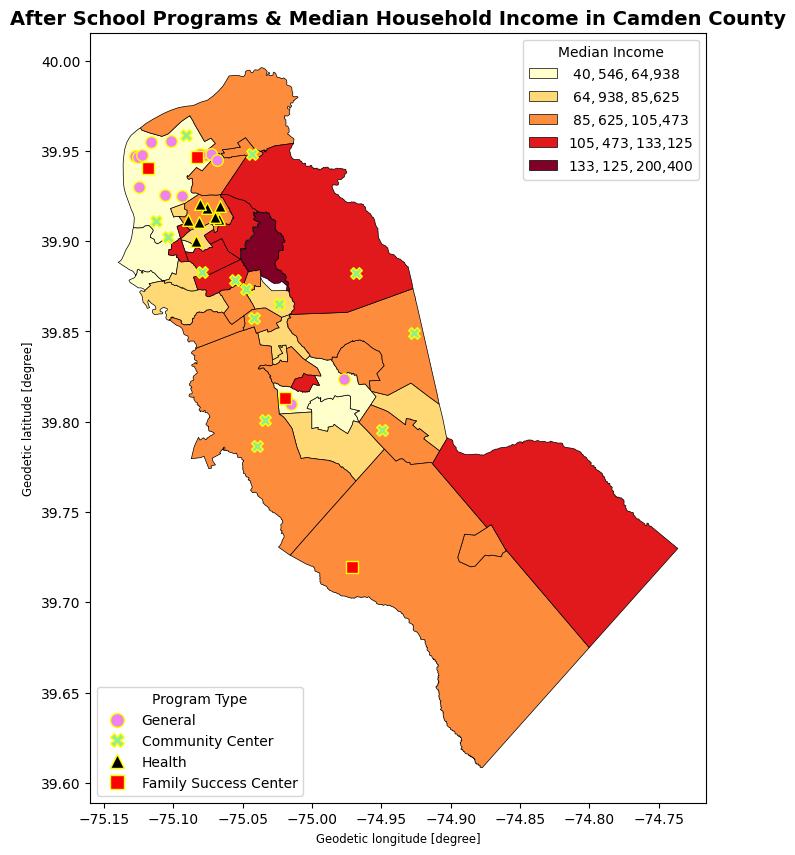

In [110]:
# 1. Align the geocoded geometries back to our original dataset
PrgGeocoded = gpd.GeoDataFrame(PrgXls, geometry=geo.geometry, crs="EPSG:4326")

# 2. Filter for each program type
PrgGen_geo = PrgGeocoded[PrgGeocoded['Prog Type'].str.strip() == 'General']
PrgCom_geo = PrgGeocoded[PrgGeocoded['Prog Type'].str.strip() == 'Community Center']
PrgHea_geo = PrgGeocoded[PrgGeocoded['Prog Type'].str.strip() == 'Health']
PrgFsc_geo = PrgGeocoded[PrgGeocoded['Prog Type'].str.strip() == 'Family Success Center']

# Ensure our regional data is numeric for choropleth mapping
a3['Median Income'] = pd.to_numeric(a3['Median Income'], errors='coerce')
a3_gpd = a3.to_crs(epsg=4326)

# 3. Create a single figure and axis to plot both background and programs
fig, ax = plt.subplots(figsize=(12, 10))

# Plot Median Household Income as the thematic background map (draws first legend)
a3_gpd.plot(
    ax=ax,
    column='Median Income',
    legend=True,
    cmap='YlOrRd',
    scheme='natural_breaks',
    k=5,
    edgecolor='black',
    linewidth=0.5,
    legend_kwds={"fmt": "${:,.0f}", "loc": "upper right", "title": "Median Income"}
)

# Keep track of the first legend so it does not get overwritten
first_legend = ax.get_legend()

# 4. Overlay each program category on the same 'ax'
PrgGen_geo.plot(ax=ax, marker='o', color='violet', markersize=70, label='General', edgecolor='yellow')
PrgCom_geo.plot(ax=ax, marker='X', color='lightgreen', markersize=70, label='Community Center', edgecolor='yellow')
PrgHea_geo.plot(ax=ax, marker='^', color='black', markersize=70, label='Health', edgecolor='yellow')
PrgFsc_geo.plot(ax=ax, marker='s', color='red', markersize=70, label='Family Success Center', edgecolor='yellow')

# Titles
plt.title('After School Programs & Median Household Income in Camden County', fontsize=14, fontweight='bold')

# 5. Create custom handles for the second legend
from matplotlib.lines import Line2D
custom_handles = [
    Line2D([0], [0], marker='o', color='yellow', markerfacecolor='violet', markersize=10, linestyle=''),
    Line2D([0], [0], marker='X', color='yellow', markerfacecolor='lightgreen', markersize=10, linestyle=''),
    Line2D([0], [0], marker='^', color='yellow', markerfacecolor='black', markersize=10, linestyle=''),
    Line2D([0], [0], marker='s', color='yellow', markerfacecolor='red', markersize=10, linestyle='')
]

# Add the second legend to the plot
second_legend = ax.legend(custom_handles, ['General', 'Community Center', 'Health', 'Family Success Center'],
                          loc='lower left', title="Program Type")

# Manually re-add the first legend back to the axes
if first_legend:
    ax.add_artist(first_legend)

plt.show()

**General** - Google Search "After School Programs for ages 14 - 16 in Camden County, NJ", offers various programs from STEM education to real-world learning activities

**Community Centers** - Google search "Community Centers in Camden County, NJ", holds various activities for children and youth

**Health** - https://www.healthykidsprograms.com/locations, concentration heavily in one area, Collingswood

**Family Success Centers** - https://www.nj.gov/dcf/divisions-offices/dfcp/fsc.shtml, "one-stop" shops with wrap-around resources for families prior to crisis.  Services include: life skills training, housing services, parent-child activities, job readiness and access to various information.



### **ECONOMICALLY DISADVANTAGED PERCENTAGE: 3 SCHOOL YEARS**
Analyzing the economically disadvantaged to identify needs within the community.

In [111]:
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
DisXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Economically%20Disadvantage%20Youth.xlsx', header = 3)

In [112]:
##identify headings of Excel file
DisXls.head(3)

,CountyCode,CountyName,DistrictCode,Municpality,DistrictName,SchoolYear,Female,Male,Non-Binary/Undesignated Gender,Economically Disadvantaged Students,Students with Disabilities,Multilingual Learners,Students Experiencing Homelessness,Students in Foster Care,Military-Connected Students,Migrant Students
0,7,Camden,150,Audubon,Audubon Public School District,2020-21,49%,51%,<=1%,16.1%,21.9%,1.0%,0.5%,0.3%,1.1%,0%
1,7,Camden,150,Audubon,Audubon Public School District,2021-22,48%,52%,<=1%,17.6%,19.4%,1.0%,0.2%,0.4%,0.2%,0%
2,7,Camden,150,Audubon,Audubon Public School District,2022-23,48%,52%,<=1%,20.3%,19.8%,1.6%,0.9%,<0.1%,0.3%,0%


In [113]:
#For School Year 2024-2025
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls1=DisXls[DisXls['SchoolYear'] =='2024-25'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls1.rename(columns={'DistrictName' : 'Muni'}, inplace=True)
DisXls1['Muni'] = DisXls1['Muni'].str.upper()
DisXls1['Muni']=DisXls1.Muni.str.strip()
DisXls1['first_word_Muni'] = DisXls1['Muni'].str.split().str[0]
DisXls1

,CountyName,DistrictCode,Muni,Economically Disadvantaged Students,first_word_Muni
4,Camden,150,AUDUBON PUBLIC SCHOOL DISTRICT,24.5%,AUDUBON
9,Camden,190,BARRINGTON SCHOOL DISTRICT,34.1%,BARRINGTON
14,Camden,260,BELLMAWR PUBLIC SCHOOL DISTRICT,57.8%,BELLMAWR
19,Camden,330,BERLIN BOROUGH SCHOOL DISTRICT,25.2%,BERLIN
24,Camden,340,BERLIN TOWNSHIP SCHOOL DISTRICT,53.3%,BERLIN
29,Camden,390,BLACK HORSE PIKE REGIONAL SCHOOL DISTRICT,44.9%,BLACK
34,Camden,580,BROOKLAWN PUBLIC SCHOOL DISTRICT,70.7%,BROOKLAWN
39,Camden,680,CAMDEN CITY SCHOOL DISTRICT,88.5%,CAMDEN
44,Camden,700,CAMDEN COUNTY TECHNICAL SCHOOL DISTRICT,56.1%,CAMDEN
49,Camden,800,CHERRY HILL SCHOOL DISTRICT,23.2%,CHERRY


In [114]:
#For School Year 2024-2025
#merged newly created columns "first_word_Muni"
a6 = pd.merge(njMun1, DisXls1, left_on=['first_word_Muni'], right_on=['first_word_Muni'], how='outer', indicator=True)
a6.columns
a6[['GEOID', 'first_word_Muni','CountyName', 'DistrictCode', 'Economically Disadvantaged Students', '_merge']]

Index(['Muni_x', 'GEOID', 'geometry', 'first_word_Muni', 'CountyName',
       'DistrictCode', 'Muni_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,first_word_Muni,CountyName,DistrictCode,Economically Disadvantaged Students,_merge
0,3400702200,AUDUBON,Camden,150.0,24.5%,both
1,3400702230,AUDUBON,Camden,150.0,24.5%,both
2,3400703250,BARRINGTON,Camden,190.0,34.1%,both
3,3400704750,BELLMAWR,Camden,260.0,57.8%,both
4,3400705440,BERLIN,Camden,330.0,25.2%,both
5,3400705440,BERLIN,Camden,340.0,53.3%,both
6,3400705470,BERLIN,Camden,330.0,25.2%,both
7,3400705470,BERLIN,Camden,340.0,53.3%,both
8,NaN,BLACK,Camden,390.0,44.9%,right_only
9,3400708170,BROOKLAWN,Camden,580.0,70.7%,both


Merge identifies Charter Schools and Regional High Schools on the right and school that did not have data regarding economic disadvantage is on the left. In addition, all schools that did not merge are different.  This indicates that the merge was a success.

In [115]:
#For School Year 2024-2025
a6._merge.value_counts()

,count
_merge,
both,41
right_only,8
left_only,3


In [116]:
#For School Year 2023-2024
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls2=DisXls[DisXls['SchoolYear'] =='2023-24'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls2.rename(columns={'DistrictName' : 'Muni'}, inplace=True)
DisXls2['Muni'] = DisXls2['Muni'].str.upper()
DisXls2['Muni']=DisXls2.Muni.str.strip()
DisXls2['first_word_Muni'] = DisXls2['Muni'].str.split().str[0]
DisXls2

,CountyName,DistrictCode,Muni,Economically Disadvantaged Students,first_word_Muni
3,Camden,150,AUDUBON PUBLIC SCHOOL DISTRICT,19.7%,AUDUBON
8,Camden,190,BARRINGTON SCHOOL DISTRICT,35.5%,BARRINGTON
13,Camden,260,BELLMAWR PUBLIC SCHOOL DISTRICT,47.4%,BELLMAWR
18,Camden,330,BERLIN BOROUGH SCHOOL DISTRICT,17.2%,BERLIN
23,Camden,340,BERLIN TOWNSHIP SCHOOL DISTRICT,36.4%,BERLIN
28,Camden,390,BLACK HORSE PIKE REGIONAL SCHOOL DISTRICT,34.3%,BLACK
33,Camden,580,BROOKLAWN PUBLIC SCHOOL DISTRICT,67.3%,BROOKLAWN
38,Camden,680,CAMDEN CITY SCHOOL DISTRICT,54.7%,CAMDEN
43,Camden,700,CAMDEN COUNTY TECHNICAL SCHOOL DISTRICT,50.2%,CAMDEN
48,Camden,800,CHERRY HILL SCHOOL DISTRICT,18.1%,CHERRY


In [117]:
#For School Year 2023-2024
#merged newly created columns "first_word_Muni"
a7 = pd.merge(njMun1, DisXls2, left_on=['first_word_Muni'], right_on=['first_word_Muni'], how='outer', indicator=True)
a7.columns
a7[['GEOID', 'first_word_Muni','CountyName', 'DistrictCode', 'Economically Disadvantaged Students', '_merge']]

Index(['Muni_x', 'GEOID', 'geometry', 'first_word_Muni', 'CountyName',
       'DistrictCode', 'Muni_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,first_word_Muni,CountyName,DistrictCode,Economically Disadvantaged Students,_merge
0,3400702200,AUDUBON,Camden,150.0,19.7%,both
1,3400702230,AUDUBON,Camden,150.0,19.7%,both
2,3400703250,BARRINGTON,Camden,190.0,35.5%,both
3,3400704750,BELLMAWR,Camden,260.0,47.4%,both
4,3400705440,BERLIN,Camden,330.0,17.2%,both
5,3400705440,BERLIN,Camden,340.0,36.4%,both
6,3400705470,BERLIN,Camden,330.0,17.2%,both
7,3400705470,BERLIN,Camden,340.0,36.4%,both
8,NaN,BLACK,Camden,390.0,34.3%,right_only
9,3400708170,BROOKLAWN,Camden,580.0,67.3%,both


In [118]:
#For School Year 2023-2024
a7._merge.value_counts()

,count
_merge,
both,41
right_only,8
left_only,3


In [119]:
#For School Year 2022-2023
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls3=DisXls[DisXls['SchoolYear'] =='2022-23'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls3.rename(columns={'DistrictName' : 'Muni'}, inplace=True)
DisXls3['Muni'] = DisXls3['Muni'].str.upper()
DisXls3['Muni']=DisXls3.Muni.str.strip()
DisXls3['first_word_Muni'] = DisXls3['Muni'].str.split().str[0]
DisXls3

,CountyName,DistrictCode,Muni,Economically Disadvantaged Students,first_word_Muni
2,Camden,150,AUDUBON PUBLIC SCHOOL DISTRICT,20.3%,AUDUBON
7,Camden,190,BARRINGTON SCHOOL DISTRICT,25.9%,BARRINGTON
12,Camden,260,BELLMAWR PUBLIC SCHOOL DISTRICT,43.9%,BELLMAWR
17,Camden,330,BERLIN BOROUGH SCHOOL DISTRICT,11.3%,BERLIN
22,Camden,340,BERLIN TOWNSHIP SCHOOL DISTRICT,41.4%,BERLIN
27,Camden,390,BLACK HORSE PIKE REGIONAL SCHOOL DISTRICT,31.3%,BLACK
32,Camden,580,BROOKLAWN PUBLIC SCHOOL DISTRICT,65.0%,BROOKLAWN
37,Camden,680,CAMDEN CITY SCHOOL DISTRICT,54.5%,CAMDEN
42,Camden,700,CAMDEN COUNTY TECHNICAL SCHOOL DISTRICT,49.5%,CAMDEN
47,Camden,800,CHERRY HILL SCHOOL DISTRICT,18.8%,CHERRY


In [120]:
#For School Year 2022-2023
#merged newly created columns "first_word_Muni"
a8 = pd.merge(njMun1, DisXls3, left_on=['first_word_Muni'], right_on=['first_word_Muni'], how='outer', indicator=True)
a8.columns
a8[['GEOID', 'first_word_Muni','CountyName', 'DistrictCode', 'Economically Disadvantaged Students', '_merge']]

Index(['Muni_x', 'GEOID', 'geometry', 'first_word_Muni', 'CountyName',
       'DistrictCode', 'Muni_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,first_word_Muni,CountyName,DistrictCode,Economically Disadvantaged Students,_merge
0,3400702200,AUDUBON,Camden,150.0,20.3%,both
1,3400702230,AUDUBON,Camden,150.0,20.3%,both
2,3400703250,BARRINGTON,Camden,190.0,25.9%,both
3,3400704750,BELLMAWR,Camden,260.0,43.9%,both
4,3400705440,BERLIN,Camden,330.0,11.3%,both
5,3400705440,BERLIN,Camden,340.0,41.4%,both
6,3400705470,BERLIN,Camden,330.0,11.3%,both
7,3400705470,BERLIN,Camden,340.0,41.4%,both
8,NaN,BLACK,Camden,390.0,31.3%,right_only
9,3400708170,BROOKLAWN,Camden,580.0,65.0%,both


In [121]:
#For School Year 2022-2023
a8._merge.value_counts()

,count
_merge,
both,41
right_only,8
left_only,3


### **SIDE BY SIDE MAPS OF LAST 3 YEARS OF ECNOMICAL DISADVANTAGED STUDENTS**

Map shows possible funding for distressed areas in 2023 - 2024 however not sufficient the following year, 2024 - 2025

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2024 - 2025 School Year')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2023 - 2024 School Year')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2022 - 2023 School Year')

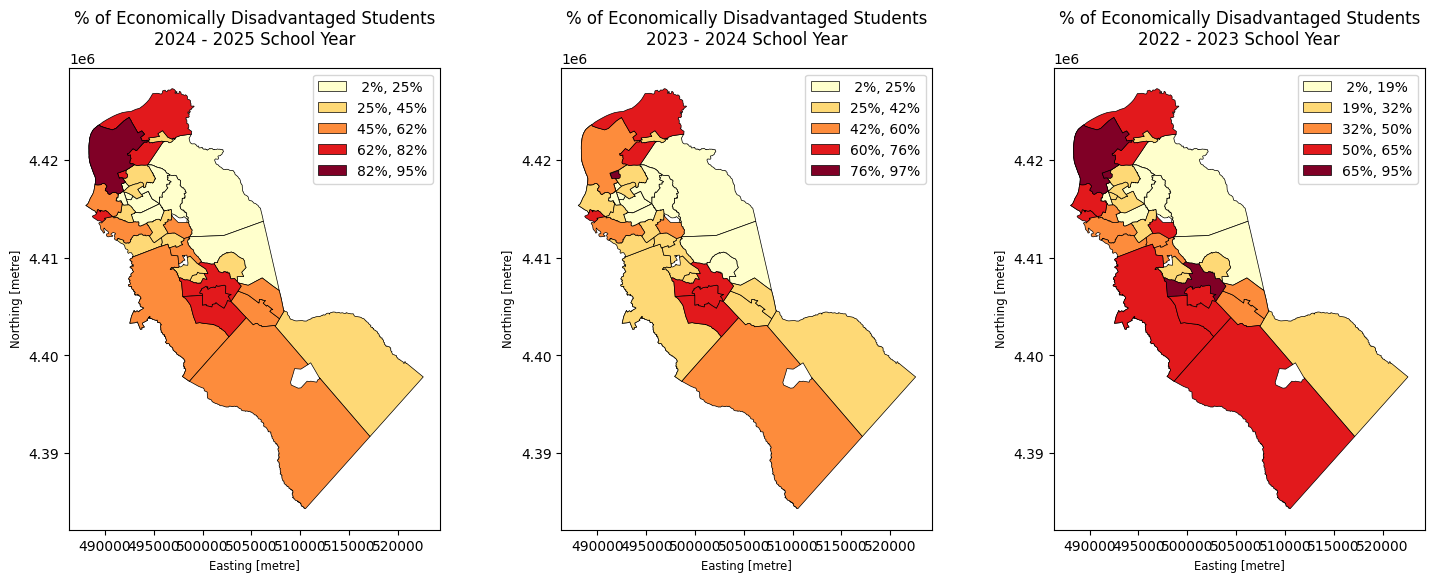

In [122]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Convert the 'Economically Disadvantaged Students' column to numeric, handling NaN values
a6['Economically Disadvantaged Students'] = a6['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a6.plot(ax=ax1, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax1.set_title('''% of Economically Disadvantaged Students\n2024 - 2025 School Year''')

# Convert the 'IncidentsPer100Students' column to numeric, handling NaN values
a7['Economically Disadvantaged Students'] = a7['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a7.plot(ax=ax2, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax2.set_title('''% of Economically Disadvantaged Students\n2023 - 2024 School Year''')

# Convert the 'IncidentsPer100Students' column to numeric, handling NaN values
a8['Economically Disadvantaged Students'] = a8['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a8.plot(ax=ax3, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax3.set_title('''% of Economically Disadvantaged Students\n2022 - 2023 School Year''')

2024 - 2025 Economic Disadvantaged Students map similar to Google search,
https://www.google.com/search?sca_esv=5b7f624190c766d8&rlz=1C1GCEA_enUS1235US1235&sxsrf=APpeQntU3iwEXsV9wxzAYXlsELOIfYDntQ:1791497138264&udm=2&fbs=ABfTbFVyMZGZf1hfvX9uKjN_-G8cY2oODYyTyZk24Xz37_7FQzcgMAXI6mDl4aLs1WJDXE-FPuVUjVB9_WO7OnpH1X7GhGoNVLROZYTxoyoqEaYuHt2NXUXO98OQTt-V2TvGCXckM2gQnUPwDRBfA-v8aogobWJe_jZQ-TcHGlO4AYGENKz-G-82f9RArff3CkNo0dCMTsjtQMqNUM69iypP9di51keTUg&q=percent+of+economically+disadvantaged+students+by+municipalities+camden+county+nj&sa=X&ved=2ahUKEwikkKr0tquXAxUVEVkFHTYNB-kQtKgLegQIGRAB&biw=1280&bih=551&dpr=1.5#sv=CAMSUxoyKhBlLU94c2hLSm45OVc5M29NMg5PeHNoS0puOTlXOTNvTToOMGFmM3RFcmgxZk80QU0gBCoXCgFzEhBlLU94c2hLSm45OVc5M29NGAEwAVACGAcgztq65QJKCBACGAEgAigB

### **IN-SCHOOL BEHAVIORAL INCIDENTS**
Analyzing youth behavior for connection to lack of after school programs

In [123]:
#in-school incidents involving violence, weapons, substance abuse and vandalism
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
BehXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School%20Incidents.xlsx', header = 3)

In [124]:
##identify headings of Excel file
BehXls.head(3)

,CountyCode,CountyName,DistrictCode,DistrictName,SchoolYear,Violence,Weapons,Vandalism,Substances,HIB,TotalUniqueIncidents,IncidentsPer100Students
0,01,Atlantic,0010,Absecon Public Schools District,2024-25,1.0,0.0,0.0,0.0,5.0,6.0,0.64
1,01,Atlantic,0110,Atlantic City School District,2024-25,130.0,12.0,4.0,36.0,22.0,204.0,3.17
2,01,Atlantic,0120,Atlantic County Vocational School District,2024-25,2.0,0.0,2.0,10.0,2.0,16.0,0.89


In [125]:
#Rename columns, make everything upper case and clear white space.  Also replace Mt. for complete word "Mount"
#Filter for both only to show 2024-2025 SchoolYear and Camden, split Muni into first word only
BehXls.rename(columns={'DistrictName': 'Muni'}, inplace=True)
BehXls['Muni'] = BehXls['Muni'].str.upper()
BehXls.loc[BehXls['Muni'] == 'MT. EPHRAIM SCHOOL DISTRICT','Muni'] = 'MOUNT EPHRAIM SCHOOL DISTRICT'
BehXls['Muni']=BehXls.Muni.str.strip()
BehXls1 = BehXls[(BehXls['SchoolYear'] == '2024-25') & (BehXls['CountyName'] == 'Camden')][['DistrictCode', 'Muni', 'IncidentsPer100Students']]
BehXls1['first_word_Muni'] = BehXls1['Muni'].str.split().str[0]
BehXls1

,DistrictCode,Muni,IncidentsPer100Students,first_word_Muni
139,0150,AUDUBON PUBLIC SCHOOL DISTRICT,1.27,AUDUBON
140,0190,BARRINGTON SCHOOL DISTRICT,0.38,BARRINGTON
141,0260,BELLMAWR PUBLIC SCHOOL DISTRICT,0.17,BELLMAWR
142,0330,BERLIN BOROUGH SCHOOL DISTRICT,1.99,BERLIN
143,0340,BERLIN TOWNSHIP SCHOOL DISTRICT,1.94,BERLIN
144,0390,BLACK HORSE PIKE REGIONAL SCHOOL DISTRICT,3.35,BLACK
145,0580,BROOKLAWN PUBLIC SCHOOL DISTRICT,1.72,BROOKLAWN
146,0680,CAMDEN CITY SCHOOL DISTRICT,4.33,CAMDEN
147,0700,CAMDEN COUNTY TECHNICAL SCHOOL DISTRICT,2.80,CAMDEN
148,0800,CHERRY HILL SCHOOL DISTRICT,1.62,CHERRY


In [126]:
#merged newly created column "first_word_Muni"
a1 = pd.merge(njMun1, BehXls1, left_on=['first_word_Muni'], right_on=['first_word_Muni'], how='outer', indicator=True)
a1

,Muni_x,GEOID,geometry,first_word_Muni,DistrictCode,Muni_y,IncidentsPer100Students,_merge
0,AUDUBON BOROUGH,3400702200,"POLYGON ((495599.23 4415536.249, 495508.749 44...",AUDUBON,0150,AUDUBON PUBLIC SCHOOL DISTRICT,1.27,both
1,AUDUBON PARK BOROUGH,3400702230,"POLYGON ((492866.221 4416337.872, 492855.687 4...",AUDUBON,0150,AUDUBON PUBLIC SCHOOL DISTRICT,1.27,both
2,BARRINGTON BOROUGH,3400703250,"POLYGON ((496819.374 4414558.505, 496827.878 4...",BARRINGTON,0190,BARRINGTON SCHOOL DISTRICT,0.38,both
3,BELLMAWR BOROUGH,3400704750,"POLYGON ((492951.896 4413667.751, 492968.147 4...",BELLMAWR,0260,BELLMAWR PUBLIC SCHOOL DISTRICT,0.17,both
4,BERLIN BOROUGH,3400705440,"POLYGON ((507881.319 4403761.193, 507873.371 4...",BERLIN,0330,BERLIN BOROUGH SCHOOL DISTRICT,1.99,both
5,BERLIN BOROUGH,3400705440,"POLYGON ((507881.319 4403761.193, 507873.371 4...",BERLIN,0340,BERLIN TOWNSHIP SCHOOL DISTRICT,1.94,both
6,BERLIN TOWNSHIP,3400705470,"POLYGON ((507848.567 4406644.366, 507978.687 4...",BERLIN,0330,BERLIN BOROUGH SCHOOL DISTRICT,1.99,both
7,BERLIN TOWNSHIP,3400705470,"POLYGON ((507848.567 4406644.366, 507978.687 4...",BERLIN,0340,BERLIN TOWNSHIP SCHOOL DISTRICT,1.94,both
8,NaN,NaN,None,BLACK,0390,BLACK HORSE PIKE REGIONAL SCHOOL DISTRICT,3.35,right_only
9,BROOKLAWN BOROUGH,3400708170,"POLYGON ((490740.818 4414218.502, 490736.285 4...",BROOKLAWN,0580,BROOKLAWN PUBLIC SCHOOL DISTRICT,1.72,both


Merge identifies Charter Schools and Regional High Schools on the right and school that did not have data regarding economic disadvantage is on the left. In addition, all schools that did not merge are different. This indicates that the merge was a success.

In [127]:
a1._merge.value_counts()

,count
_merge,
both,41
right_only,8
left_only,3


### **2024 - 2025 SIDE BY SIDE MAPS OF ECNOMICAL DISADVANTAGED STUDENTS AND SCHOOL INCIDENTS**

Economic disadvantaged students aand school incidents are very similar showing correlation

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2024 - 2025 School Year')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

Text(0.5, 1.0, '% of Incidents Per 100 Students\n2024 - 2025 School Year')

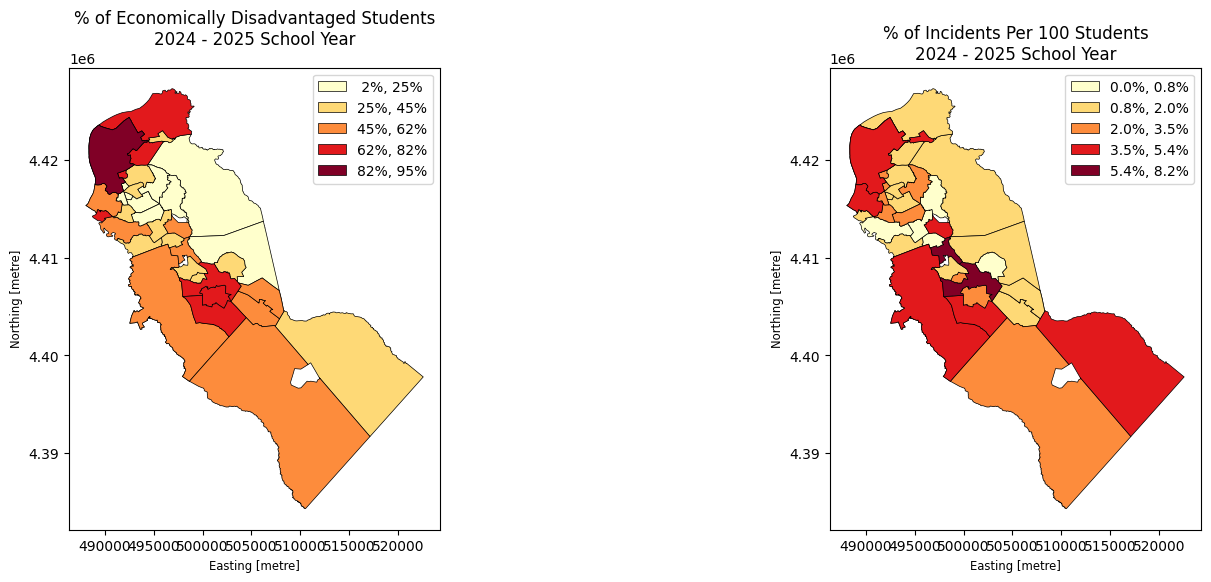

In [128]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Convert the 'Economically Disadvantaged Students' column to numeric, handling NaN values
a6['Economically Disadvantaged Students'] = a6['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a6.plot(ax=ax1, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax1.set_title('''% of Economically Disadvantaged Students\n2024 - 2025 School Year''')

# Convert the 'IncidentsPer100Students' column to numeric, handling NaN values
a1['IncidentsPer100Students'] = a1['IncidentsPer100Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a1.plot(ax=ax2, column='IncidentsPer100Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.1f}%"})
ax2.set_title('''% of Incidents Per 100 Students\n2024 - 2025 School Year''')


### **ABSENTEEISM**

In [129]:
#in-school incidents involving violence, weapons, substance abuse and vandalism
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
AbsXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Chronic%20Absenteeism%20by%20Grade.xlsx', header = 3)

In [130]:
AbsXls.head(3)

,CountyCode,CountyName,DistrictCode,DistrictName,SchoolYear,Grade,ChronicAbsenteeismRate_District,ChronicAbsenteeismRate_State
0,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 1,18.7%,14.3%
1,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 2,6.9%,12.7%
2,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 3,12.7%,11.6%


In [131]:
# 1. Rename columns, make everything upper case and clear white space
AbsXls.rename(columns={'DistrictName': 'Muni'}, inplace=True)
AbsXls['Muni'] = AbsXls['Muni'].str.upper()
AbsXls.loc[AbsXls['Muni'] == 'MT. EPHRAIM SCHOOL DISTRICT','Muni'] = 'MOUNT EPHRAIM SCHOOL DISTRICT'
AbsXls['Muni'] = AbsXls['Muni'].str.strip()

# 2. Filter for high school grades in Camden County
grades_to_keep = ['Grade 9', 'Grade 10', 'Grade 11', 'Grade 12']
AbsFiltered = AbsXls[AbsXls['Grade'].isin(grades_to_keep) & (AbsXls['CountyName'] == 'Camden')].copy()

# 3. Convert absenteeism rate to numeric float for calculation
AbsFiltered['ChronicAbsenteeismRate_District'] = AbsFiltered['ChronicAbsenteeismRate_District'].astype(str).str.replace('%', '').str.strip()
AbsFiltered['ChronicAbsenteeismRate_District'] = pd.to_numeric(AbsFiltered['ChronicAbsenteeismRate_District'], errors='coerce')

# 4. Group grades together as 1 average rate per municipality
AbsXls1 = AbsFiltered.groupby(['DistrictCode', 'Muni'], as_index=False)['ChronicAbsenteeismRate_District'].mean()

# 5. Extract first word safely from the grouped result
AbsXls1['first_word_Muni'] = AbsXls1['Muni'].str.split().str[0]
AbsXls1

,DistrictCode,Muni,ChronicAbsenteeismRate_District,first_word_Muni
0,0150,AUDUBON PUBLIC SCHOOL DISTRICT,12.250,AUDUBON
1,0390,BLACK HORSE PIKE REGIONAL SCHOOL DISTRICT,6.625,BLACK
2,0680,CAMDEN CITY SCHOOL DISTRICT,56.675,CAMDEN
3,0700,CAMDEN COUNTY TECHNICAL SCHOOL DISTRICT,9.800,CAMDEN
4,0800,CHERRY HILL SCHOOL DISTRICT,16.875,CHERRY
5,0940,COLLINGSWOOD PUBLIC SCHOOL DISTRICT,17.250,COLLINGSWOOD
6,1255,EASTERN CAMDEN COUNTY REGIONAL SCHOOL DISTRICT,16.425,EASTERN
7,1770,GLOUCESTER CITY PUBLIC SCHOOL DISTRICT,22.825,GLOUCESTER
8,1799,"KIPP: COOPER NORCROSS, A NEW JERSEY NONPROFIT ...",62.100,KIPP:
9,1801,"CAMDEN PREP, INC.",69.000,CAMDEN


In [132]:
#merged newly created column "first_word_Muni"
a4 = pd.merge(njMun1, AbsXls1, left_on=['first_word_Muni'], right_on=['first_word_Muni'], how='outer', indicator=True)
a4

,Muni_x,GEOID,geometry,first_word_Muni,DistrictCode,Muni_y,ChronicAbsenteeismRate_District,_merge
0,AUDUBON BOROUGH,3400702200,"POLYGON ((495599.23 4415536.249, 495508.749 44...",AUDUBON,0150,AUDUBON PUBLIC SCHOOL DISTRICT,12.250,both
1,AUDUBON PARK BOROUGH,3400702230,"POLYGON ((492866.221 4416337.872, 492855.687 4...",AUDUBON,0150,AUDUBON PUBLIC SCHOOL DISTRICT,12.250,both
2,BARRINGTON BOROUGH,3400703250,"POLYGON ((496819.374 4414558.505, 496827.878 4...",BARRINGTON,NaN,NaN,NaN,left_only
3,BELLMAWR BOROUGH,3400704750,"POLYGON ((492951.896 4413667.751, 492968.147 4...",BELLMAWR,NaN,NaN,NaN,left_only
4,BERLIN BOROUGH,3400705440,"POLYGON ((507881.319 4403761.193, 507873.371 4...",BERLIN,NaN,NaN,NaN,left_only
5,BERLIN TOWNSHIP,3400705470,"POLYGON ((507848.567 4406644.366, 507978.687 4...",BERLIN,NaN,NaN,NaN,left_only
6,NaN,NaN,None,BLACK,0390,BLACK HORSE PIKE REGIONAL SCHOOL DISTRICT,6.625,right_only
7,BROOKLAWN BOROUGH,3400708170,"POLYGON ((490740.818 4414218.502, 490736.285 4...",BROOKLAWN,NaN,NaN,NaN,left_only
8,CAMDEN CITY,3400710000,"POLYGON ((493032.266 4419551.728, 492897.768 4...",CAMDEN,0680,CAMDEN CITY SCHOOL DISTRICT,56.675,both
9,CAMDEN CITY,3400710000,"POLYGON ((493032.266 4419551.728, 492897.768 4...",CAMDEN,0700,CAMDEN COUNTY TECHNICAL SCHOOL DISTRICT,9.800,both


No data for schools merged to the left.  Schools on the right are Charter or Regional High Schools

In [133]:
a4._merge.value_counts()

,count
_merge,
left_only,22
both,18
right_only,7


### **CHRONIC ABSENTEEISM FOR STUDENTS IN ECONOMICALLY DISADVANTAGED COMMUNITIES**

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\nwith Chronic Absenteeism Rates (Blue Dots)')

[]

[]

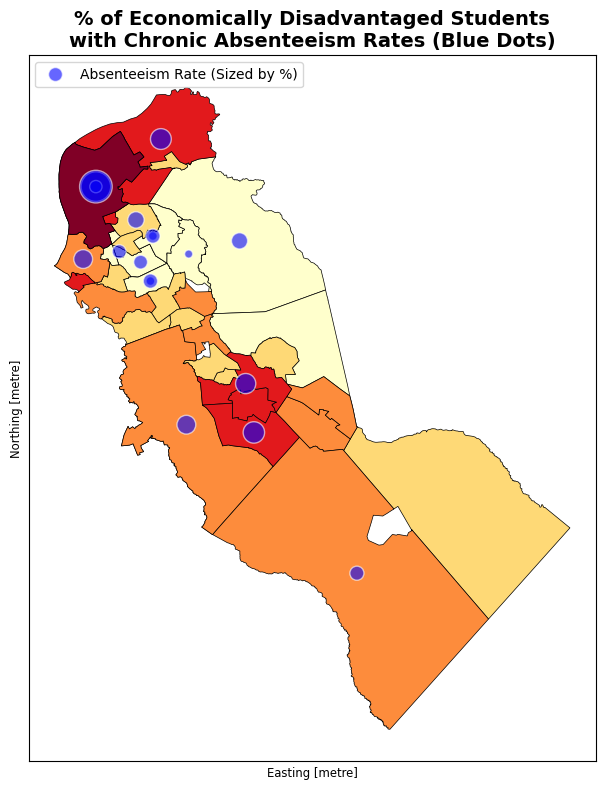

In [134]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patheffects import withStroke

# 1. Clean data and merge with municipal boundaries to define abs_geo
AbsXls1_clean = AbsXls1.copy()
if AbsXls1_clean['ChronicAbsenteeismRate_District'].dtype == object:
    AbsXls1_clean['ChronicAbsenteeismRate_District'] = pd.to_numeric(AbsXls1_clean['ChronicAbsenteeismRate_District'].astype(str).str.replace('%', '').str.strip(), errors='coerce')

abs_geo = gpd.GeoDataFrame(pd.merge(njMun1, AbsXls1_clean, on='first_word_Muni', how='inner'), crs=njMun1.crs)

# Ensure background dataset a6 has numeric values
a6_gpd = a6.copy()
if a6_gpd['Economically Disadvantaged Students'].dtype == object:
    a6_gpd['Economically Disadvantaged Students'] = pd.to_numeric(a6_gpd['Economically Disadvantaged Students'].astype(str).str.replace('%', '').str.strip(), errors='coerce')

# 2. Compute centroids for the absenteeism dots
abs_geo['centroid'] = abs_geo.geometry.centroid
abs_centroids = abs_geo.set_geometry('centroid')

# 3. Create the single-panel overlay map
fig, ax = plt.subplots(1, figsize=(10, 8))

# Plot background: Economically Disadvantaged Students
a6_gpd.plot(ax=ax, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
             scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5,
             legend_kwds={"fmt": "{:.0f}%", "loc": "lower right", "title": "Eco. Disadvantaged %"})

# Plot overlay: Chronic Absenteeism as sized blue dots at the municipality centroids
abs_centroids.plot(ax=ax, color='blue', markersize=abs_centroids['ChronicAbsenteeismRate_District'] * 8,
                   alpha=0.6, edgecolor='white', linewidth=1)


# Titles & Legend configurations
ax.set_title('% of Economically Disadvantaged Students\nwith Chronic Absenteeism Rates (Blue Dots)', fontsize=14, fontweight='bold')
ax.set_xticks([]); ax.set_yticks([])

from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', label='Absenteeism Rate (Sized by %)',
                          markerfacecolor='blue', markersize=10, alpha=0.6, markeredgecolor='white')]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()

### **SCATTERPLOT OF INCIDENTS, ECONOMIC DISADVANTAGE AND MEDIAN INCOME**
Shows Lindenwold with high incidnets and economic disadvantage with a low median household income.

In [135]:
import plotly.express as px
import pandas as pd

# 1. Clean and prepare individual datasets
dis_df = DisXls1_clean.copy() if 'DisXls1_clean' in globals() else DisXls1.copy()
dis_df['Economically Disadvantaged Students'] = pd.to_numeric(dis_df['Economically Disadvantaged Students'].astype(str).str.replace('%', ''), errors='coerce')

beh_df = BehXls1.copy()
beh_df['IncidentsPer100Students'] = pd.to_numeric(beh_df['IncidentsPer100Students'], errors='coerce')

inc_df = IncXls1.copy()
inc_df['Median Income'] = pd.to_numeric(inc_df['Median Income'], errors='coerce')

# 2. Merge variables on first_word_Muni or Muni
merged_data = pd.merge(dis_df[['first_word_Muni', 'Economically Disadvantaged Students']],
                       beh_df[['first_word_Muni', 'IncidentsPer100Students']],
                       on='first_word_Muni', how='inner')

# Safely extract first word of municipality name in income dataset to match
inc_df['first_word_Muni'] = inc_df['Muni'].str.split().str[0]
plot_data = pd.merge(merged_data, inc_df[['first_word_Muni', 'Median Income', 'Muni']],
                     on='first_word_Muni', how='inner')

# 3. Create interactive scatter plot
fig = px.scatter(
    plot_data,
    x="Economically Disadvantaged Students",
    y="IncidentsPer100Students",
    color="Median Income",
    hover_data=["Muni"],
    title="Economic Disadvantage vs. School Incidents by Municipality in Camden County",
    color_continuous_scale="Viridis",
    width=1000,
    height=600
)

fig.show()